# Strategy metrics control

Synthetic daily series isolate the economic metrics from the backtester.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..").resolve()))

from evaluation.strategy import (
    evaluate_strategy,
    rolling_volatility,
    sharpe_difference_test,
    spanning_test,
)

In [2]:
TRADING_DAYS = 252
TARGET_VOL = 0.10
rng = np.random.default_rng(42)
dates = pd.bdate_range("2020-01-02", periods=3 * TRADING_DAYS)
rf = pd.Series((1.03 ** (1 / TRADING_DAYS) - 1), index=dates)
regime_vol = 0.012 + 0.008 * (1 + np.sin(np.arange(len(dates)) / 35))
benchmark = pd.Series(
    0.0003 + regime_vol * rng.standard_normal(len(dates)), index=dates
)
controlled = pd.Series(
    rf.to_numpy()
    + 0.0002
    + TARGET_VOL / np.sqrt(TRADING_DAYS) * rng.standard_normal(len(dates)),
    index=dates,
)
turnover = pd.Series(0.01 * np.abs(np.sin(np.arange(len(dates)) / 12)), index=dates)
zero_turnover = pd.Series(0.0, index=dates)

In [3]:
metrics = pd.DataFrame(
    {
        "controlled": evaluate_strategy(controlled, rf, turnover, TARGET_VOL),
        "benchmark": evaluate_strategy(benchmark, rf, zero_turnover, TARGET_VOL),
    }
).T
assert metrics.loc["controlled", "vol_of_vol"] < metrics.loc["benchmark", "vol_of_vol"]
metrics

,sharpe,maximum_drawdown,annualized_turnover,realized_volatility,target_volatility_gap,vol_of_vol,worst_return_1,worst_return_2,worst_return_3,worst_return_4,worst_return_5,skew,kurtosis
controlled,0.515129,-0.101580,1.600282,0.101202,0.001202,0.015376,-0.022666,-0.018301,-0.018144,-0.017743,-0.017182,-0.142759,0.173477
benchmark,-0.448624,-0.562364,0.000000,0.333778,0.233778,0.238887,-0.081892,-0.068878,-0.063167,-0.062080,-0.059393,-0.014964,0.788412


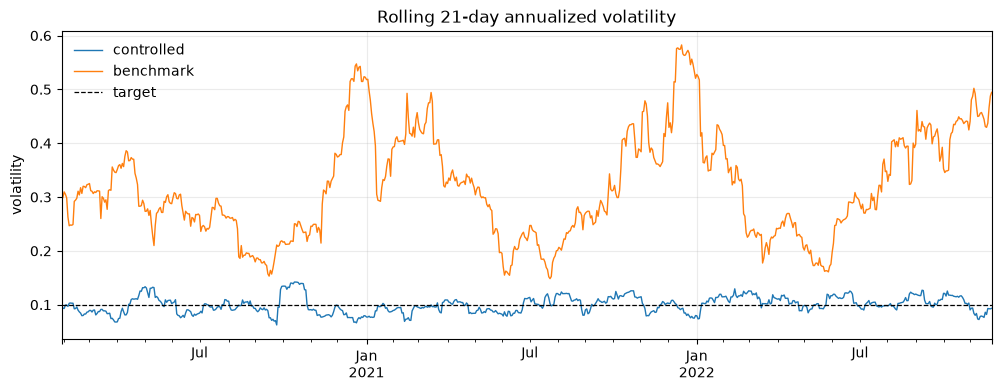

In [4]:
rolling = pd.DataFrame(
    {
        "controlled": rolling_volatility(controlled),
        "benchmark": rolling_volatility(benchmark),
    }
)
ax = rolling.plot(figsize=(12, 4), lw=1.0)
ax.axhline(TARGET_VOL, color="black", ls="--", lw=0.9, label="target")
ax.set_title("Rolling 21-day annualized volatility")
ax.set_ylabel("volatility")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.show()

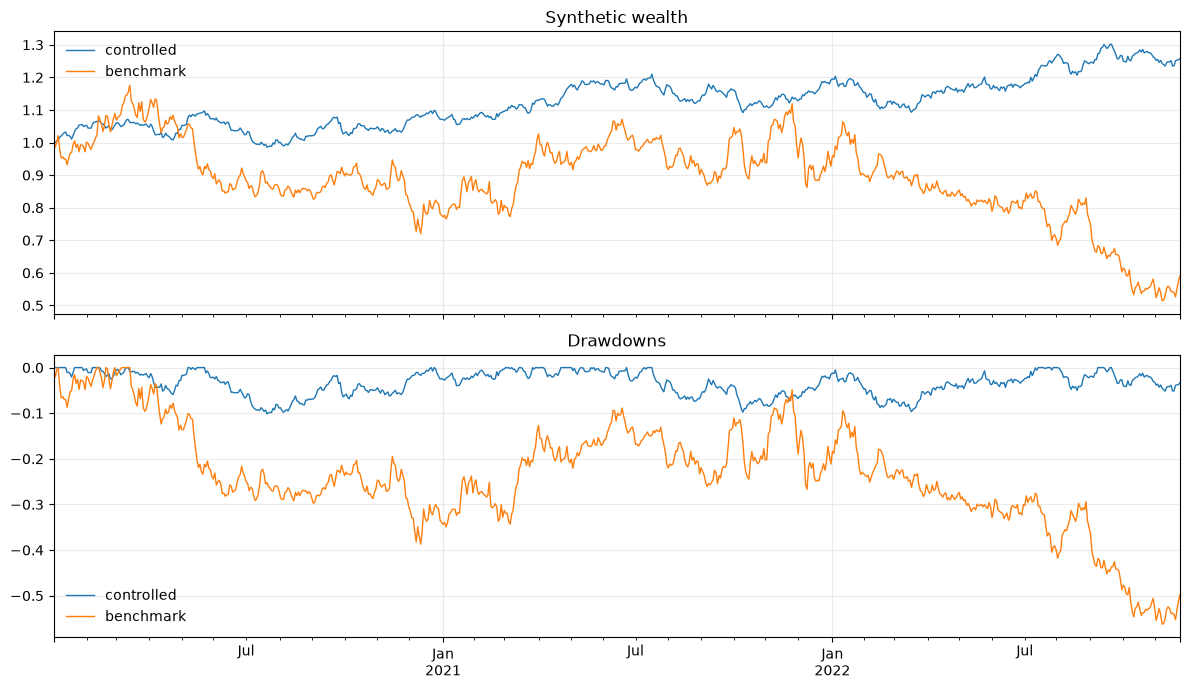

In [5]:
returns = pd.DataFrame({"controlled": controlled, "benchmark": benchmark})
wealth = (1.0 + returns).cumprod()
drawdowns = wealth / wealth.cummax() - 1.0
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
wealth.plot(ax=axes[0], lw=1.0, title="Synthetic wealth")
drawdowns.plot(ax=axes[1], lw=1.0, title="Drawdowns")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
fig.tight_layout()
plt.show()

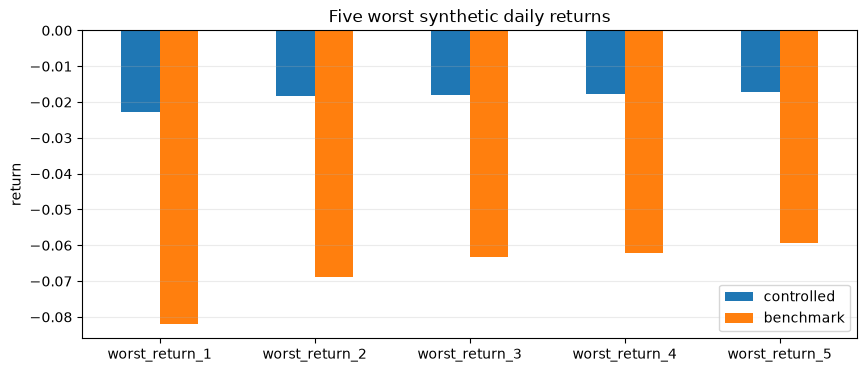

In [6]:
worst = metrics.filter(like="worst_return").T
ax = worst.plot.bar(figsize=(10, 4))
ax.set_title("Five worst synthetic daily returns")
ax.set_ylabel("return")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.show()

In [7]:
spanning = spanning_test(controlled, benchmark, rf)
sharpe_test = sharpe_difference_test(
    controlled,
    benchmark,
    rf,
    bootstrap_reps=499,
    seed=42,
)
assert 0.0 <= spanning["alpha_pvalue"] <= 1.0
assert 0.0 <= sharpe_test["pvalue"] <= 1.0
pd.concat({"spanning": spanning, "sharpe_difference": sharpe_test}, axis=1)

,spanning,sharpe_difference
alpha_daily,0.000207,NaN
alpha_annual,0.052108,NaN
beta,-0.000099,NaN
alpha_stat,0.812625,NaN
alpha_pvalue,0.416433,NaN
newey_west_lag,4.000000,NaN
sharpe_difference,NaN,0.964391
statistic,NaN,1.076030
pvalue,NaN,0.254000
block_size,NaN,16.000000
